# Lab 12-01 · Differential Pairs

Companion to [chapter 12-01](../../chapters/12-01-differential-pairs.md). Four parts: large-signal transfer of BJT and MOS pairs, small-signal gains and CMRR from the full circuit, a Monte Carlo offset budget, and bipolar offset drift with and without trimming. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

VT = 1.380649e-23 * 300 / 1.602176634e-19    # 25.852 mV
VTN = 0.5
rng = np.random.default_rng(12011)

## Part 1 · Large-signal transfer

Each split is found by solving Kirchhoff's current law at the shared emitter or source node with the tail fixing the total current. The curves are then compared with the closed forms of §3.1 and §3.2.

largest deviation from tanh: 1.5e-14
largest deviation from the square-law formula: 1.3e-15


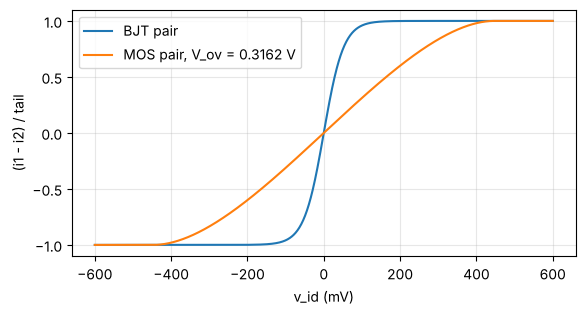

In [2]:
def bjt_split(vid, IEE, IS1=1e-15, IS2=1e-15, vt=VT):
    f = lambda ve: IS1 * math.exp((vid / 2 - ve) / vt) + IS2 * math.exp((-vid / 2 - ve) / vt) - IEE
    ve = brentq(f, -2.0, 2.0, xtol=1e-15)
    return IS1 * math.exp((vid / 2 - ve) / vt), IS2 * math.exp((-vid / 2 - ve) / vt)


def mos_split(vid, ISS, kn1, kn2=None, vtn1=VTN, vtn2=VTN, vic=1.0):
    kn2 = kn1 if kn2 is None else kn2
    sq = lambda k, vov: 0.5 * k * max(vov, 0.0) ** 2
    f = lambda vs: sq(kn1, vic + vid / 2 - vs - vtn1) + sq(kn2, vic - vid / 2 - vs - vtn2) - ISS
    vs = brentq(f, -5.0, vic + abs(vid) + 1.0, xtol=1e-15)
    return sq(kn1, vic + vid / 2 - vs - vtn1), sq(kn2, vic - vid / 2 - vs - vtn2)


x = np.linspace(-0.6, 0.6, 1201)
bjt = np.array([(lambda p: p[0] - p[1])(bjt_split(xi, 1e-3)) for xi in x]) / 1e-3
kn, ISS = 2e-3, 200e-6
vov = math.sqrt(ISS / kn)
mos = np.array([(lambda p: p[0] - p[1])(mos_split(xi, ISS, kn)) for xi in x]) / ISS
bjt_formula = np.tanh(x / (2 * VT))
mos_formula = np.where(np.abs(x) <= math.sqrt(2) * vov,
                       kn * x / 2 * np.sqrt(np.clip(4 * ISS / kn - x ** 2, 0, None)) / ISS, np.sign(x))
print(f"largest deviation from tanh: {np.max(np.abs(bjt - bjt_formula)):.1e}")
print(f"largest deviation from the square-law formula: {np.max(np.abs(mos - mos_formula)):.1e}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(x * 1e3, bjt, label="BJT pair")
ax.plot(x * 1e3, mos, label=f"MOS pair, V_ov = {vov:.4f} V")
ax.set_xlabel("v_id (mV)"); ax.set_ylabel("(i1 - i2) / tail"); ax.grid(True, alpha=0.3); ax.legend()
plt.show()

**What to notice.** Both solved curves match their formulas to rounding. The BJT pair has switched by about ±100 mV; the MOS pair needs ±√2 $V_{ov}$ = ±0.447 V.

## Part 2 · Gains and CMRR from the full circuit

Modified nodal analysis of the two transistors, their drain loads and the tail resistance, with no half-circuit assumptions. The pair is Example 12-01.2's with a 50 kΩ tail (Example 12-01.3).

In [3]:
def mna_pair(gm1, gm2, RD1, RD2, RSS, vg1, vg2):
    G = np.zeros((3, 3)); b = np.zeros(3)
    G[0, 0] += 1 / RD1; G[1, 1] += 1 / RD2; G[2, 2] += 1 / RSS
    for d, gm, vg in ((0, gm1, vg1), (1, gm2, vg2)):
        G[d, 2] -= gm; b[d] -= gm * vg; G[2, 2] += gm; b[2] += gm * vg
    return np.linalg.solve(G, b)


gm = math.sqrt(kn * ISS)
RD, RSS = 10e3, 50e3
d = mna_pair(gm, gm, RD, RD, RSS, 0.5, -0.5)
c = mna_pair(gm, gm, RD, RD, RSS, 1.0, 1.0)
print(f"differential gain {abs(d[0] - d[1]):.3f}, single-ended {abs(d[0]):.3f}, common-mode {abs(c[0]):.5f}")
print(f"single-ended CMRR {abs(d[0]) / abs(c[0]):.2f} = {20 * math.log10(abs(d[0]) / abs(c[0])):.1f} dB")
for mism in (0.001, 0.01, 0.05):
    dm = mna_pair(gm, gm, RD * (1 + mism / 2), RD * (1 - mism / 2), RSS, 0.5, -0.5)
    cm = mna_pair(gm, gm, RD * (1 + mism / 2), RD * (1 - mism / 2), RSS, 1.0, 1.0)
    r = abs(dm[0] - dm[1]) / abs(cm[0] - cm[1])
    print(f"load mismatch {100 * mism:4.1f}%: differential CMRR {r:9.0f} = {20 * math.log10(r):5.1f} dB")

differential gain 6.325, single-ended 3.162, common-mode 0.09844
single-ended CMRR 32.12 = 30.1 dB
load mismatch  0.1%: differential CMRR     64246 =  96.2 dB
load mismatch  1.0%: differential CMRR      6425 =  76.2 dB
load mismatch  5.0%: differential CMRR      1285 =  62.2 dB


**What to notice.** The differential CMRR falls by 20 dB for every tenfold increase in mismatch: with a differential output, matching, not the tail, sets the rejection.

## Part 3 · Monte Carlo offset (the chapter's guided exercise)

**Predict first:** in Example 12-01.4's budget, if you halve the overdrive by making $W$ four times wider at the same $L$ and current, does σ($V_{OS}$) fall, and by about how much?

Each trial draws a threshold mismatch with Pelgrom's σ = $A_{VT}/\sqrt{WL}$, a current-factor mismatch and a load mismatch, then solves for the input that balances the outputs.

RSS budget: 2.086 mV;  Monte Carlo sigma: 2.08 mV over 4000 trials


half overdrive: RSS budget 0.985 mV;  Monte Carlo sigma 0.97 mV


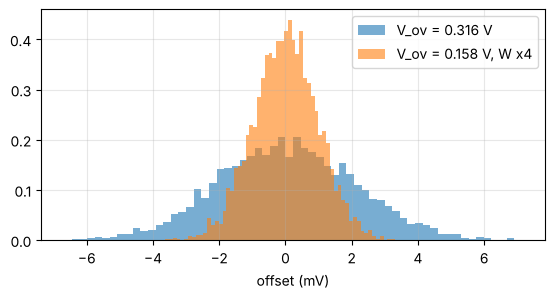

In [4]:
def mos_offset(dvt, dk, dR, ISS=200e-6, kn=2e-3, RD=10e3):
    def vod(x):
        a, b = mos_split(x, ISS, kn * (1 + dk / 2), kn * (1 - dk / 2), VTN + dvt / 2, VTN - dvt / 2)
        return a * RD * (1 + dR / 2) - b * RD * (1 - dR / 2)
    return brentq(vod, -0.2, 0.2, xtol=1e-15)


AVT = 3.5e-3                      # V*um, illustrative (as in 10-08)
s_vt, s_k, s_R = AVT / math.sqrt(20 * 0.5), 0.005, 0.01
budget = math.sqrt(s_vt ** 2 + (vov / 2 * s_R) ** 2 + (vov / 2 * s_k) ** 2)
N = 4000
mc = np.array([mos_offset(rng.normal(0, s_vt), rng.normal(0, s_k), rng.normal(0, s_R)) for _ in range(N)])
print(f"RSS budget: {budget * 1e3:.3f} mV;  Monte Carlo sigma: {mc.std() * 1e3:.2f} mV over {N} trials")
# half the overdrive: kn four times larger (W x4), so the area is four times larger too
s_vt4, s_k4 = AVT / math.sqrt(80 * 0.5), s_k / 2
budget_half = math.sqrt(s_vt4 ** 2 + (vov / 4 * s_R) ** 2 + (vov / 4 * s_k4) ** 2)
mc_half = np.array([mos_offset(rng.normal(0, s_vt4), rng.normal(0, s_k4), rng.normal(0, s_R), kn=8e-3)
                    for _ in range(N)])
print(f"half overdrive: RSS budget {budget_half * 1e3:.3f} mV;  Monte Carlo sigma {mc_half.std() * 1e3:.2f} mV")
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.hist(mc * 1e3, bins=60, alpha=0.6, density=True, label="V_ov = 0.316 V")
ax.hist(mc_half * 1e3, bins=60, alpha=0.6, density=True, label="V_ov = 0.158 V, W x4")
ax.set_xlabel("offset (mV)"); ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

**What to notice.** The simulated spread matches the first-order budget. Halving the overdrive cuts σ by a little more than half: the load term halves, the area halves the threshold term, and the current-factor term falls fourfold.

## Part 4 · Bipolar offset drift and trimming

A pair whose $I_S$ values differ so that $V_{OS}$ = 1.0 mV at 300 K is evaluated from 250 K to 400 K, untrimmed, trimmed by a collector-resistor ratio at 300 K, and trimmed by a fixed voltage at 300 K.

In [5]:
kB, q = 1.380649e-23, 1.602176634e-19


def bjt_offset(dIS, dR, T):
    vt = kB * T / q
    def vod(x):
        a, b = bjt_split(x, 1e-3, 1e-15 * (1 + dIS / 2), 1e-15 * (1 - dIS / 2), vt)
        return a * (1 + dR / 2) - b * (1 - dR / 2)
    return brentq(vod, -0.2, 0.2, xtol=1e-15)


dIS = brentq(lambda d: abs(bjt_offset(d, 0.0, 300)) - 1e-3, 1e-4, 0.2, xtol=1e-14)
dR = brentq(lambda r: bjt_offset(dIS, r, 300), -0.2, 0.2, xtol=1e-15)
fixed = bjt_offset(dIS, 0.0, 300)
T = np.linspace(250, 400, 7)
for Ti in T:
    raw = bjt_offset(dIS, 0.0, Ti)
    print(f"T = {Ti:5.0f} K: untrimmed {raw * 1e3:+.4f} mV, ratio-trimmed {bjt_offset(dIS, dR, Ti) * 1e6:+.4f} uV, "
          f"voltage-trimmed {(raw - fixed) * 1e3:+.4f} mV")

T =   250 K: untrimmed -0.8333 mV, ratio-trimmed +0.0000 uV, voltage-trimmed +0.1667 mV
T =   275 K: untrimmed -0.9167 mV, ratio-trimmed +0.0000 uV, voltage-trimmed +0.0833 mV
T =   300 K: untrimmed -1.0000 mV, ratio-trimmed +0.0000 uV, voltage-trimmed +0.0000 mV
T =   325 K: untrimmed -1.0833 mV, ratio-trimmed -0.0000 uV, voltage-trimmed -0.0833 mV
T =   350 K: untrimmed -1.1667 mV, ratio-trimmed -0.0000 uV, voltage-trimmed -0.1667 mV
T =   375 K: untrimmed -1.2500 mV, ratio-trimmed -0.0000 uV, voltage-trimmed -0.2500 mV
T =   400 K: untrimmed -1.3333 mV, ratio-trimmed -0.0000 uV, voltage-trimmed -0.3333 mV


**What to take away.** The pair steers a fixed current: a BJT pair over a few $V_T$, a MOS pair over √2 $V_{ov}$. A differential output's CMRR is set by matching. Random offset follows an RSS budget that the simulation confirms. And a trim that scales with temperature removes the drift with the offset; a fixed one does not.